### Bussiness Problem

Chronic kidney disease (CKD) often goes unnoticed until the kidneys are badly damaged, which makes treatment costly and late. Doctors have to read many lab results by hand to spot it, which takes time and can lead to missed cases. This project builds a machine learning model that uses patient clinical and lab data to predict whether a patient has CKD or not.

### Bussiness Statement

Hospitals and diagnostic centers collect routine blood and urine test results, but identifying chronic kidney disease (CKD) from them depends on manual review, and many cases are found only after serious kidney damage. Late diagnosis leads to expensive treatment such as dialysis or a transplant, and a worse outcome for the patient.

The business goal is to use this existing test data to build a machine learning model that flags patients likely to have CKD early. This will support doctors in screening, speed up decisions and reduce the cost of late-stage treatment.

### Objective

1. Build a binary classification model that predicts CKD (ckd) or no CKD (notckd) from patient data.
2. Handle missing values, encoding and scaling inside a single pipeline.
3. Compare several algorithms using cross-validation and tune the best one with hyperparameter tuning.
4. Achieve high recall on the CKD class, so that real patients are not missed.
5. Identify which clinical measurements matter most for the prediction.
6. Deploy the final model as a simple Streamlit app.

### Data Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\DAMODAR\Downloads\chronic_kidney_disease_full_names.csv")
pd.set_option('display.max_columns', None)
df

,age,blood_pressure,specific_gravity,albumin,sugar,red_blood_cells,pus_cell,pus_cell_clumps,bacteria,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,hemoglobin,packed_cell_volume,white_blood_cell_count,red_blood_cell_count,hypertension,diabetes_mellitus,coronary_artery_disease,appetite,pedal_edema,anemia,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35.0,7300.0,4.6,no,no,no,good,no,no,ckd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,55.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,140.0,49.0,0.5,150.0,4.9,15.7,47.0,6700.0,4.9,no,no,no,good,no,no,notckd
396,42.0,70.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,75.0,31.0,1.2,141.0,3.5,16.5,54.0,7800.0,6.2,no,no,no,good,no,no,notckd
397,12.0,80.0,1.020,0.0,0.0,normal,normal,notpresent,notpresent,100.0,26.0,0.6,137.0,4.4,15.8,49.0,6600.0,5.4,no,no,no,good,no,no,notckd
398,17.0,60.0,1.025,0.0,0.0,normal,normal,notpresent,notpresent,114.0,50.0,1.0,135.0,4.9,14.2,51.0,7200.0,5.9,no,no,no,good,no,no,notckd


In [3]:
df.shape

(400, 25)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      391 non-null    float64
 1   blood_pressure           388 non-null    float64
 2   specific_gravity         353 non-null    float64
 3   albumin                  354 non-null    float64
 4   sugar                    351 non-null    float64
 5   red_blood_cells          248 non-null    object 
 6   pus_cell                 335 non-null    object 
 7   pus_cell_clumps          396 non-null    object 
 8   bacteria                 396 non-null    object 
 9   blood_glucose_random     356 non-null    float64
 10  blood_urea               381 non-null    float64
 11  serum_creatinine         383 non-null    float64
 12  sodium                   313 non-null    float64
 13  potassium                312 non-null    float64
 14  hemoglobin               3

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isna().sum()

age                          9
blood_pressure              12
specific_gravity            47
albumin                     46
sugar                       49
red_blood_cells            152
pus_cell                    65
pus_cell_clumps              4
bacteria                     4
blood_glucose_random        44
blood_urea                  19
serum_creatinine            17
sodium                      87
potassium                   88
hemoglobin                  52
packed_cell_volume          71
white_blood_cell_count     106
red_blood_cell_count       131
hypertension                 2
diabetes_mellitus            2
coronary_artery_disease      2
appetite                     1
pedal_edema                  1
anemia                       1
class                        0
dtype: int64

In [7]:
df.describe()

,age,blood_pressure,specific_gravity,albumin,sugar,blood_glucose_random,blood_urea,serum_creatinine,sodium,potassium,hemoglobin,packed_cell_volume,white_blood_cell_count,red_blood_cell_count
count,391.000000,388.000000,353.000000,354.000000,351.000000,356.000000,381.000000,383.000000,313.000000,312.000000,348.000000,329.000000,294.000000,269.000000
mean,51.483376,76.469072,1.017408,1.016949,0.450142,148.036517,57.425722,3.072454,137.528754,4.627244,12.526437,38.884498,8406.122449,4.707435
std,17.169714,13.683637,0.005717,1.352679,1.099191,79.281714,50.503006,5.741126,10.408752,3.193904,2.912587,8.990105,2944.474190,1.025323
min,2.000000,50.000000,1.005000,0.000000,0.000000,22.000000,1.500000,0.400000,4.500000,2.500000,3.100000,9.000000,2200.000000,2.100000
25%,42.000000,70.000000,1.010000,0.000000,0.000000,99.000000,27.000000,0.900000,135.000000,3.800000,10.300000,32.000000,6500.000000,3.900000
50%,55.000000,80.000000,1.020000,0.000000,0.000000,121.000000,42.000000,1.300000,138.000000,4.400000,12.650000,40.000000,8000.000000,4.800000
75%,64.500000,80.000000,1.020000,2.000000,0.000000,163.000000,66.000000,2.800000,142.000000,4.900000,15.000000,45.000000,9800.000000,5.400000
max,90.000000,180.000000,1.025000,5.000000,5.000000,490.000000,391.000000,76.000000,163.000000,47.000000,17.800000,54.000000,26400.000000,8.000000


In [8]:
cat_cols = ['red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'hypertension',
            'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'pedal_edema', 'anemia', 'class']

In [9]:
for col in cat_cols:
    print(col, df[col].dropna().unique())

red_blood_cells ['normal' 'abnormal']
pus_cell ['normal' 'abnormal']
pus_cell_clumps ['notpresent' 'present']
bacteria ['notpresent' 'present']
hypertension ['yes' 'no']
diabetes_mellitus ['yes' 'no']
coronary_artery_disease ['no' 'yes']
appetite ['good' 'poor']
pedal_edema ['no' 'yes']
anemia ['no' 'yes']
class ['ckd' 'notckd']


In [10]:
df['class']=df['class'].map({'notckd':0,'ckd':1})

In [11]:
df['class'].value_counts()

class
1    250
0    150
Name: count, dtype: int64

In [12]:
X=df.drop(columns='class')
y=df['class']

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=23)

In [15]:
X_train.shape, X_test.shape

((320, 24), (80, 24))

### EDA

#### Univariate Analysis

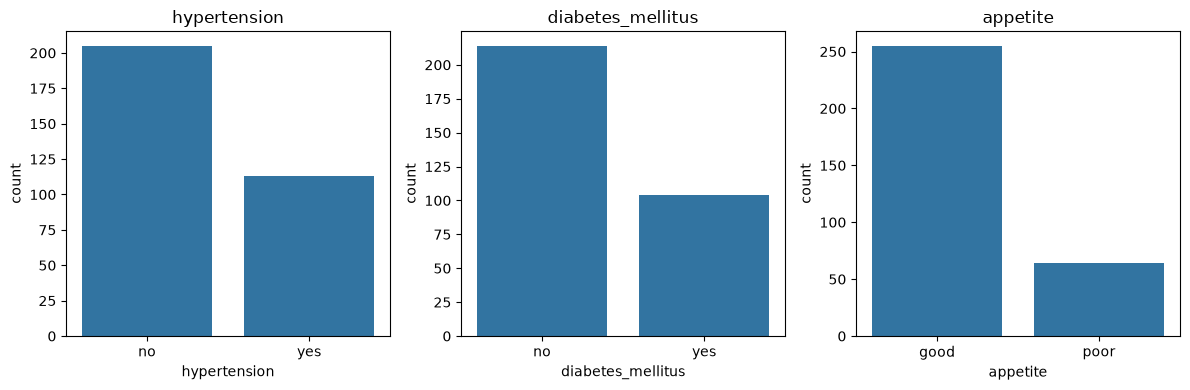

In [16]:
plt.figure(figsize=(12, 4))
plt.subplot(131)
sns.countplot(x=X_train['hypertension'])
plt.title('hypertension')
plt.subplot(132)
sns.countplot(x=X_train['diabetes_mellitus'])
plt.title('diabetes_mellitus')
plt.subplot(133)
sns.countplot(x=X_train['appetite'])
plt.title('appetite')
plt.tight_layout()
plt.show()


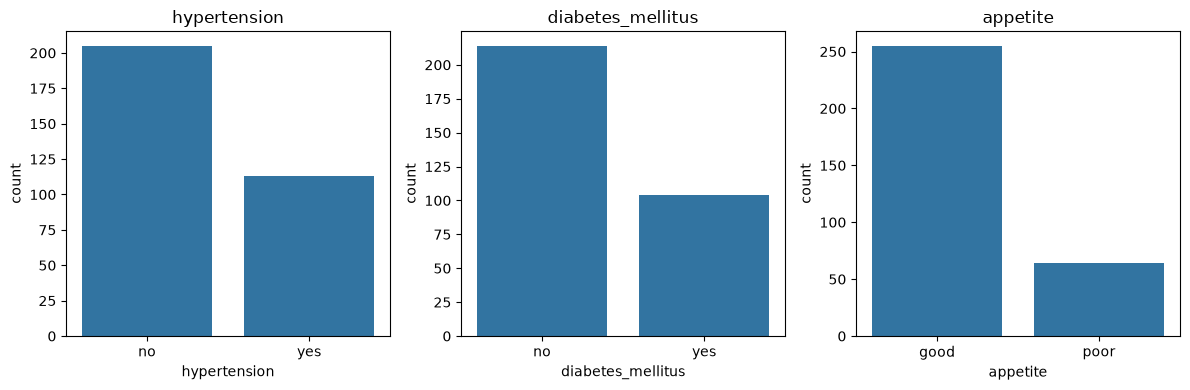

In [17]:
plt.figure(figsize=(12, 4))
plt.subplot(131)
sns.countplot(x=X_train['hypertension'])
plt.title('hypertension')
plt.subplot(132)
sns.countplot(x=X_train['diabetes_mellitus'])
plt.title('diabetes_mellitus')
plt.subplot(133)
sns.countplot(x=X_train['appetite'])
plt.title('appetite')
plt.tight_layout()
plt.show()

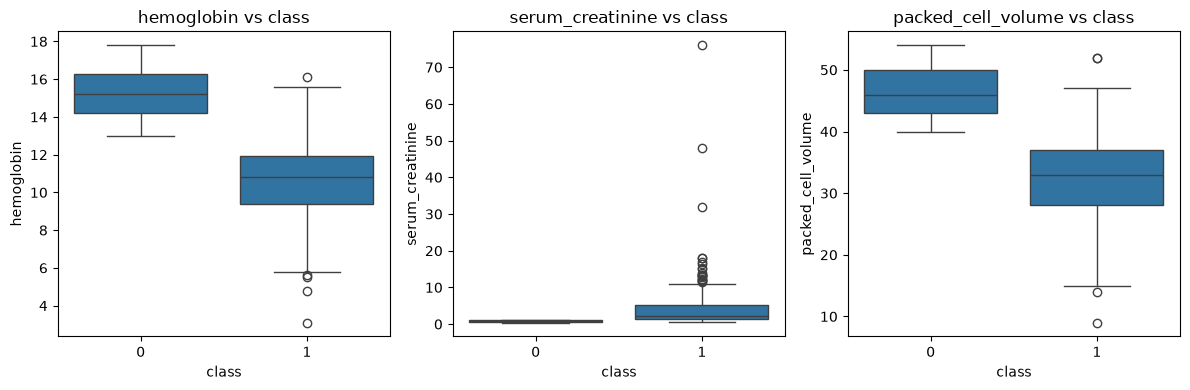

In [18]:
plt.figure(figsize=(12, 4))
plt.subplot(131)
sns.boxplot(x=y_train, y=X_train['hemoglobin'])
plt.title('hemoglobin vs class')
plt.subplot(132)
sns.boxplot(x=y_train, y=X_train['serum_creatinine'])
plt.title('serum_creatinine vs class')
plt.subplot(133)
sns.boxplot(x=y_train, y=X_train['packed_cell_volume'])
plt.title('packed_cell_volume vs class')
plt.tight_layout()
plt.show()

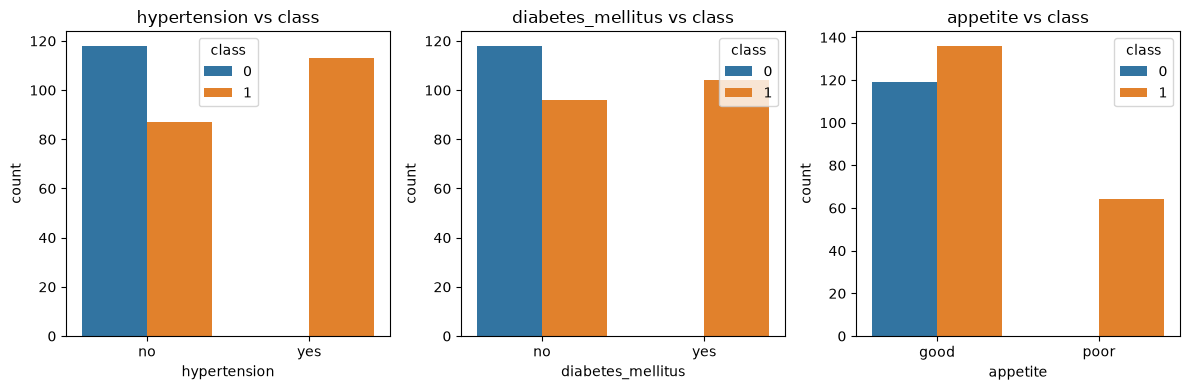

In [19]:
plt.figure(figsize=(12, 4))
plt.subplot(131)
sns.countplot(x=X_train['hypertension'], hue=y_train)
plt.title('hypertension vs class')
plt.subplot(132)
sns.countplot(x=X_train['diabetes_mellitus'], hue=y_train)
plt.title('diabetes_mellitus vs class')
plt.subplot(133)
sns.countplot(x=X_train['appetite'], hue=y_train)
plt.title('appetite vs class')
plt.tight_layout()
plt.show()

### Data preprocessing using pipeline

In [20]:
num_cols = ['age', 'blood_pressure', 'blood_glucose_random', 'blood_urea', 'serum_creatinine', 'sodium',
            'potassium', 'hemoglobin', 'packed_cell_volume', 'white_blood_cell_count', 'red_blood_cell_count']

ord_cols = ['specific_gravity', 'albumin', 'sugar']

nom_cols = ['red_blood_cells', 'pus_cell', 'pus_cell_clumps', 'bacteria', 'hypertension',
            'diabetes_mellitus', 'coronary_artery_disease', 'appetite', 'pedal_edema', 'anemia']

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

In [22]:
num_pipe=Pipeline(steps=[('Imputation',SimpleImputer(strategy='median')),
                         ('Scaling',StandardScaler())
])
num_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Scaling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto accoun

In [23]:
cat_order=[[1.005, 1.010, 1.015, 1.020, 1.025],[0, 1, 2, 3, 4, 5],[0, 1, 2, 3, 4, 5]]

In [24]:
ord_pipe=Pipeline(steps=[('Imputation',SimpleImputer(strategy='most_frequent')),
                         ('Ordinalencoding',OrdinalEncoder(categories=cat_order))
])
ord_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Ordinalencoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive est

In [25]:
nom_pipe = Pipeline(steps=[
    ('Imputation', SimpleImputer(strategy='most_frequent')),
    ('Nominal Encoding', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])
nom_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Nominal Encoding', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive es

In [26]:
preprocessor = ColumnTransformer(transformers=[
    ('Numeric', num_pipe, num_cols),
    ('Ordinal', ord_pipe, ord_cols),
    ('Nominal', nom_pipe, nom_cols)
])

In [27]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('Numeric', ...), ('Ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``f

In [28]:
X_train_transformed = preprocessor.fit_transform(X_train)

In [29]:
X_train_transformed

array([[-0.67360694,  0.3442808 , -0.04289873, ...,  0.        ,
         0.        ,  0.        ],
       [ 0.14710535, -1.22957429,  2.9419726 , ...,  1.        ,
         1.        ,  0.        ],
       [ 1.84715223, -0.44264674, -0.57792283, ...,  1.        ,
         0.        ,  1.        ],
       ...,
       [ 1.20230686,  1.13120834, -0.26817203, ...,  0.        ,
         0.        ,  0.        ],
       [-0.55636232,  0.3442808 , -0.63424116, ...,  0.        ,
         0.        ,  0.        ],
       [ 1.26092917, -0.44264674, -1.02846945, ...,  0.        ,
         1.        ,  0.        ]], shape=(320, 24))

In [30]:
X_test_transformed = preprocessor.transform(X_test)

In [31]:
    X_test_transformed

array([[-0.38049541,  1.13120834,  3.05460926, ...,  0.        ,
         0.        ,  0.        ],
       [-0.84947385,  1.91813589, -0.31745057, ...,  0.        ,
         0.        ,  0.        ],
       [-2.31503151, -1.22957429, -0.31745057, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.85057302, -0.44264674,  4.27953287, ...,  0.        ,
         0.        ,  0.        ],
       [-0.26325079,  0.3442808 , -0.40896785, ...,  1.        ,
         0.        ,  0.        ],
       [-1.78743075, -0.44264674, -0.31745057, ...,  1.        ,
         0.        ,  1.        ]], shape=(80, 24))

In [32]:
X_train_transformed.shape, X_test_transformed.shape

((320, 24), (80, 24))

### Model Building

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV, GridSearchCV


In [34]:
lr_model = Pipeline([('Data Preprocessing', preprocessor),
                     ('Model Building', LogisticRegression(random_state=42, max_iter=1000))])
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

Accuracy: 0.9875 Precision: 1.0 Recall: 0.98 F1: 0.98989898989899


In [35]:
knn_model = Pipeline([('Data Preprocessing', preprocessor),
                      ('Model Building', KNeighborsClassifier())])
knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

Accuracy: 0.9625 Precision: 1.0 Recall: 0.94 F1: 0.9690721649484536


In [36]:
dt_model = Pipeline([('Data Preprocessing', preprocessor),
                     ('Model Building', DecisionTreeClassifier(random_state=42))])
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

Accuracy: 0.9875 Precision: 1.0 Recall: 0.98 F1: 0.98989898989899


In [37]:
svc_model = Pipeline([('Data Preprocessing', preprocessor),
                      ('Model Building', SVC(random_state=42))])
svc_model.fit(X_train, y_train)
y_pred = svc_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

Accuracy: 0.9875 Precision: 1.0 Recall: 0.98 F1: 0.98989898989899


In [38]:
nb_model = Pipeline([('Data Preprocessing', preprocessor),
                     ('Model Building', GaussianNB())])
nb_model.fit(X_train, y_train)
y_pred = nb_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

Accuracy: 0.9625 Precision: 1.0 Recall: 0.94 F1: 0.9690721649484536


In [39]:
rf_model = Pipeline([('Data Preprocessing', preprocessor),
                     ('Model Building', RandomForestClassifier(random_state=42, n_jobs=-1))])
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

Accuracy: 1.0 Precision: 1.0 Recall: 1.0 F1: 1.0


In [40]:
xg_model = Pipeline([('Data Preprocessing', preprocessor),
                     ('Model Building', XGBClassifier(random_state=42, n_jobs=-1))])
xg_model.fit(X_train, y_train)
y_pred = xg_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

Accuracy: 1.0 Precision: 1.0 Recall: 1.0 F1: 1.0


### Cross Validation 

In [41]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=23)

In [42]:
xg_model = Pipeline([('Data Preprocessing', preprocessor),
                     ('Model Building', XGBClassifier(random_state=42))])
cross_val_score(xg_model, X_train, y_train, scoring='recall', cv=skf).mean()

np.float64(0.99)

In [43]:
models = {'Logistic Regression': lr_model, 'KNN': knn_model, 'Decision Tree': dt_model,
          'SVC': svc_model, 'Naive Bayes': nb_model, 'Random Forest': rf_model,'XGBoost': xg_model}

In [44]:
cv_results = []
for name, model in models.items():
    acc = cross_val_score(model, X_train, y_train, scoring='accuracy', cv=skf).mean()
    rec = cross_val_score(model, X_train, y_train, scoring='recall', cv=skf)
    f1 = cross_val_score(model, X_train, y_train, scoring='f1', cv=skf).mean()
    cv_results.append([name, acc, rec.mean(), rec.std(), f1])

In [45]:
cv_df = pd.DataFrame(cv_results, columns=['Model', 'Accuracy', 'Recall', 'Recall Std', 'F1'])
cv_df.sort_values(by='Recall', ascending=False)

,Model,Accuracy,Recall,Recall Std,F1
5,Random Forest,0.987500,0.995,0.010000,0.990122
6,XGBoost,0.984375,0.990,0.020000,0.987467
0,Logistic Regression,0.990625,0.990,0.012247,0.992468
3,SVC,0.990625,0.985,0.012247,0.992405
2,Decision Tree,0.965625,0.975,0.015811,0.972708
4,Naive Bayes,0.965625,0.945,0.029155,0.971490
1,KNN,0.953125,0.925,0.041833,0.960551


### Hyperparameter tuning

In [46]:
lr_space = {'Model Building__C': [0.01, 0.1, 1, 10, 100],
            'Model Building__solver': ['lbfgs', 'liblinear']}

In [47]:
lr_grid = GridSearchCV(estimator=lr_model, param_grid=lr_space,
                       scoring='recall', cv=skf, n_jobs=-1)
lr_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model Building__C': [0.01, 0.1, ...], 'Model Building__solver': ['lbfgs', 'liblinear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose

In [48]:
lr_grid.best_params_, lr_grid.best_score_

({'Model Building__C': 1, 'Model Building__solver': 'lbfgs'}, np.float64(0.99))

In [49]:
svc_space = {'Model Building__C': [0.1, 1, 10, 100],
             'Model Building__kernel': ['linear', 'rbf'],
             'Model Building__gamma': ['scale', 'auto']}

In [50]:
svc_grid = GridSearchCV(estimator=svc_model, param_grid=svc_space,
                        scoring='recall', cv=skf, n_jobs=-1)
svc_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model Building__C': [0.1, 1, ...], 'Model Building__gamma': ['scale', 'auto'], 'Model Building__kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support

In [51]:
svc_grid.best_params_, svc_grid.best_score_

({'Model Building__C': 0.1,
  'Model Building__gamma': 'scale',
  'Model Building__kernel': 'linear'},
 np.float64(0.99))

In [52]:
rf_space = {'Model Building__n_estimators': range(100, 501, 100),
            'Model Building__max_depth': [None, 5, 10, 15],
            'Model Building__min_samples_split': [2, 5, 10],
            'Model Building__min_samples_leaf': [1, 2, 4],
            'Model Building__max_features': ['sqrt', 'log2', 0.5]}

In [53]:
rf_random = RandomizedSearchCV(estimator=rf_model, param_distributions=rf_space,
                               n_iter=20, scoring='recall', cv=skf, random_state=23, n_jobs=-1)
rf_random.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'Model Building__max_depth': [None, 5, ...], 'Model Building__max_features': ['sqrt', 'log2', ...], 'Model Building__min_samples_leaf': [1, 2, ...], 'Model Building__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",23
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estima

In [54]:
xgb_space = {'Model Building__n_estimators': range(100, 501, 100),
             'Model Building__max_depth': [3, 4, 6, 8],
             'Model Building__learning_rate': [0.03, 0.05, 0.1],
             'Model Building__subsample': [0.7, 0.8, 1.0],
             'Model Building__colsample_bytree': [0.5, 0.7, 1.0],
             'Model Building__min_child_weight': [1, 3, 5],
             'Model Building__reg_lambda': [1, 5, 10]}

In [55]:
xgb_random = RandomizedSearchCV(estimator=xg_model, param_distributions=xgb_space,
                                n_iter=20, scoring='recall', cv=skf, random_state=23, n_jobs=-1)
xgb_random.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'Model Building__colsample_bytree': [0.5, 0.7, ...], 'Model Building__learning_rate': [0.03, 0.05, ...], 'Model Building__max_depth': [3, 4, ...], 'Model Building__min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",23
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimat

In [56]:
xgb_random.best_params_, xgb_random.best_score_

({'Model Building__subsample': 0.8,
  'Model Building__reg_lambda': 5,
  'Model Building__n_estimators': 300,
  'Model Building__min_child_weight': 1,
  'Model Building__max_depth': 6,
  'Model Building__learning_rate': 0.03,
  'Model Building__colsample_bytree': 1.0},
 np.float64(0.99))

In [58]:
knn_space = {'Model Building__n_neighbors': [3, 5, 7, 9, 11],
             'Model Building__weights': ['uniform', 'distance'],
             'Model Building__p': [1, 2]}

In [59]:
knn_grid = GridSearchCV(estimator=knn_model, param_grid=knn_space,
                        scoring='recall', cv=skf, n_jobs=-1)
knn_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model Building__n_neighbors': [3, 5, ...], 'Model Building__p': [1, 2], 'Model Building__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support

In [60]:
knn_grid.best_params_, knn_grid.best_score_

({'Model Building__n_neighbors': 3,
  'Model Building__p': 1,
  'Model Building__weights': 'uniform'},
 np.float64(0.9550000000000001))

In [61]:
dt_space = {'Model Building__criterion': ['gini', 'entropy'],
            'Model Building__max_depth': [None, 3, 5, 7, 10],
            'Model Building__min_samples_split': [2, 5, 10],
            'Model Building__min_samples_leaf': [1, 2, 4]}

In [62]:
dt_grid = GridSearchCV(estimator=dt_model, param_grid=dt_space,
                       scoring='recall', cv=skf, n_jobs=-1)
dt_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'Model Building__criterion': ['gini', 'entropy'], 'Model Building__max_depth': [None, 3, ...], 'Model Building__min_samples_leaf': [1, 2, ...], 'Model Building__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance model

In [63]:
dt_grid.best_params_, dt_grid.best_score_

({'Model Building__criterion': 'gini',
  'Model Building__max_depth': None,
  'Model Building__min_samples_leaf': 1,
  'Model Building__min_samples_split': 5},
 np.float64(0.9850000000000001))

In [64]:
nb_space = {'Model Building__var_smoothing': np.logspace(-9, -1, 9)}

In [65]:
nb_grid = GridSearchCV(estimator=nb_model, param_grid=nb_space,
                       scoring='recall', cv=skf, n_jobs=-1)
nb_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...aussianNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'Model Building__var_smoothing': array([1.e-09... 1.e-01])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'recall'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Control

In [66]:
nb_grid.best_params_, nb_grid.best_score_

({'Model Building__var_smoothing': np.float64(1e-09)},
 np.float64(0.9450000000000001))

In [67]:
tuned_models = {'Logistic Regression': lr_grid, 'KNN': knn_grid, 'Decision Tree': dt_grid,
                'SVC': svc_grid, 'Naive Bayes': nb_grid, 'Random Forest': rf_random,
                'XGBoost': xgb_random}
tuned_results = []
for name, search in tuned_models.items():
    y_pred = search.best_estimator_.predict(X_test)
    tuned_results.append([name, search.best_score_, accuracy_score(y_test, y_pred),
                          precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred)])

In [68]:
pd.DataFrame(tuned_results, columns=['Model', 'CV Recall', 'Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1'])

,Model,CV Recall,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic Regression,0.990,0.9875,1.0,0.98,0.989899
1,KNN,0.955,0.9875,1.0,0.98,0.989899
2,Decision Tree,0.985,0.9875,1.0,0.98,0.989899
3,SVC,0.990,0.9750,1.0,0.96,0.979592
4,Naive Bayes,0.945,0.9625,1.0,0.94,0.969072
5,Random Forest,0.995,1.0000,1.0,1.00,1.000000
6,XGBoost,0.990,1.0000,1.0,1.00,1.000000


### Deployment

In [ ]:
final_model = rf_random.best_estimator_
final_model

In [ ]:
rf_random.best_params_, rf_random.best_score_

In [ ]:
y_pred = final_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred),
      "Precision:", precision_score(y_test, y_pred),
      "Recall:", recall_score(y_test, y_pred),
      "F1:", f1_score(y_test, y_pred))

In [ ]:
import pickle

with open('ckd_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)